# M01 — Correcciones de estaciones gravimétricas

**Level 2 · Prerrequisitos: notebook de fundamentos; lectura: 25 minutos.**

## Objetivos

Esta lección ejecuta el procesador de estaciones del producto sobre su control analítico versionado. Calcula perturbación de Bouguer, no inversión de densidad. Gravedad positiva hacia abajo en mGal; alturas elipsoidales WGS84 positivas hacia arriba. El control original no es dato de campo.

## Preparación

Use el entorno pipeline Python 3.12 ya revisado. Este notebook no instala nada.

Importe el código del repositorio y confirme su archivo fuente.

In [1]:
import json, sys
from pathlib import Path
root=Path.cwd().parents[2]; sys.path.insert(0,str(root/'data-pipeline'))
from gravity_processing import process_survey
# Identify the implementation loaded from this repository.
print('Módulo del producto:', Path(__import__('gravity_processing').__file__).name)


Módulo del producto: gravity_processing.py


## Datos

Esta lección ejecuta el procesador de estaciones del producto sobre su control analítico versionado. Calcula perturbación de Bouguer, no inversión de densidad. Gravedad positiva hacia abajo en mGal; alturas elipsoidales WGS84 positivas hacia arriba. El control original no es dato de campo.

**Files:** docs/methods/gravity-processing/examples/station-control.json

## Método

Para latitud φ y altura del receptor h, D=g−γ(φ,h). La atracción de placa terrestre infinita es B=2πGρt×10⁵ mGal, con G en m³ kg⁻¹ s⁻², ρ en kg m⁻³ y espesor superficial t en m. La salida es D_B=D−B. Altura del receptor y espesor de terreno son distintos; no es corrección automática de aire libre ni DEM.

Sea h la altura elipsoidal del receptor y s la altura superficial usada por la placa. Los términos ordenados son −γ(φ,0), γ(φ,0)−γ(φ,h) y −2πGρs. Su suma transforma g absoluta en perturbación de Bouguer. El procesador guarda adiciones y hashes exactos para reconstruir el estado anterior y rechazar correcciones duplicadas o reordenadas. Ese historial es científicamente importante: una segunda aplicación restaría gravedad normal y placa otra vez, aunque generara números visualmente plausibles.

Para errores primitivos independientes, la propagación de primer orden es σ²_out=∑ᵢ(∂y/∂xᵢ)²σ²ᵢ. La política marginal conservadora suma contribuciones absolutas, ∑ᵢ|∂y/∂xᵢ|σᵢ; no exige independencia, pero no es un modelo de covarianza. Ambas son condicionales a las sigmas entregadas. La implementación excluye terreno regional, incertidumbre del campo de referencia, sesgo de fuente e incertidumbre geológica. El control de una estación puede probar unidades, orden, historial determinista y rechazo, pero no validar un mapa regional, detección de atípicos ni aptitud de campo.


Ejecute el método del producto sobre el control declarado.

In [2]:
request=json.loads((root/'docs/methods/gravity-processing/examples/station-control.json').read_text(encoding='utf-8'))
# Execute the product correction core on its committed analytic control.
result=process_survey(request['dataset'],request['config'])
print({'estado':result['dataset']['state'],'gravedad_derivada_mGal':result['qc']['derived_mgal'],'incertidumbre_mGal':result['processing']['uncertainty_mgal'],'aceptado':result['processing']['full_method_accepted']})

{'estado': 'bouguer_disturbance', 'gravedad_derivada_mGal': [12.000000000024315], 'incertidumbre_mGal': [1.148909022890369], 'aceptado': False}


Control adversarial/negativo: aísle un supuesto o incumpla una restricción física declarada.

In [3]:
try:
    process_survey(result['dataset'],request['config'])
except ValueError as error:
    # Reapplying an already reached correction state must be refused.
    print('Rechazo esperado por corrección duplicada:',str(error))
else:
    raise AssertionError('Repeated correction was accepted')

Rechazo esperado por corrección duplicada: config.target: double correction or backwards processing rejected


El manual USGS describe adquisición y QA previas ([TM 2-D4](https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf)); Harmonica documenta la atracción de placa ([referencia API](https://www.fatiando.org/harmonica/latest/api/index.html)). La incertidumbre condicional propaga errores marginales declarados; no es confianza geológica. Una estación analítica no evalúa mapas regionales, terreno ni elegibilidad de campo.

La celda gráfica reutiliza el resultado real de `process_survey` y vuelve a ejecutarlo solo con la otra agregación de error declarada. Todas las barras están en mGal; la figura es un control analítico de una estación, no un mapa de corrección espacial.


historial registrado: ['normal_reference', 'elevation_reference', 'bouguer_plate']
estado final: bouguer_disturbance aceptado: False


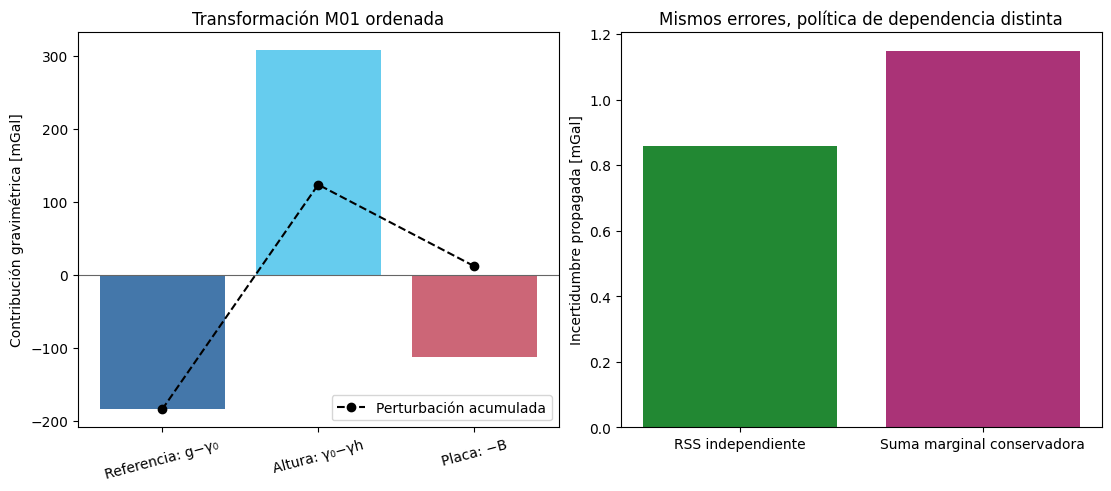

In [4]:
import copy
import numpy as np
import matplotlib.pyplot as plt

# Descomponer el historial real del pipeline y comparar las dos políticas implementadas de incertidumbre.
h = result['dataset']['history']; g = request['dataset']['stations'][0]['value_mgal']
terminos = [g + h[0]['additions_mgal'][0], h[1]['additions_mgal'][0], h[2]['additions_mgal'][0]]
acumulada = np.cumsum(terminos)
otra = copy.deepcopy(request['config']); otra['uncertainty_model'] = 'independent_first_order'
independiente = process_survey(request['dataset'], otra)
fig,(ax,bx)=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)
etiq=['Referencia: g−γ₀','Altura: γ₀−γh','Placa: −B']
ax.bar(etiq,terminos,color=['#4477aa','#66ccee','#cc6677']); ax.plot(range(3),acumulada,'ko--',label='Perturbación acumulada')
ax.axhline(0,color='.4',lw=.8); ax.set(ylabel='Contribución gravimétrica [mGal]',title='Transformación M01 ordenada'); ax.tick_params(axis='x',rotation=15); ax.legend()
bx.bar(['RSS independiente','Suma marginal conservadora'],[independiente['processing']['uncertainty_mgal'][0],result['processing']['uncertainty_mgal'][0]],color=['#228833','#aa3377'])
bx.set(ylabel='Incertidumbre propagada [mGal]',title='Mismos errores, política de dependencia distinta')
print('historial registrado:',[x['name'] for x in h]); print('estado final:',result['dataset']['state'],'aceptado:',result['processing']['full_method_accepted'])
plt.show()


## Resultados

Se esperan cerca de 12 mGal, una historia ordenada y `full_method_accepted=false`. Reaplicar debe fallar. Esto es evidencia local de aritmética/estado, no aceptación M01 completa.

## Resumen

Una corrección es transformación tipada y ordenada. Conserve unidades, referencia, valor original e historia; nunca infiera metadatos faltantes por magnitud.




## Referencias

- https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf
- https://www.fatiando.org/harmonica/latest/api/index.html